# Task 1: Target Selection & Scraping

> 1.1 Data Selection: Choose one disaster category (Earthquakes, Tsunamis, Floods, Cyclones, Volcanoes, Droughts, or Forest Fires) and choose two different regions.




> 1.2 The "Source of Truth" Scraper: Identify two specific events from those two regions:
> * Event A: A "Historical" event (at least 5–8 years old).
> * Event B: A "Recent" event (within the last 12 months).

In [1]:
import requests

URL = "https://www.gdacs.org/Alerts/default.aspx"
page = requests.get(URL)

print(page.text)



<!DOCTYPE html>

<html xmlns="http://www.w3.org/1999/xhtml">
<head><title>
	GDACS - Global Disaster Awareness and Coordination System
</title>
    <link rel="stylesheet" href="../scripts/openlayers/3.20.1/ol.css" type="text/css" />
    <link rel="stylesheet" href="../scripts/openlayers/layerswitcher/ol3-layerswitcher.css" />
    <link href="../Styles/gdacs_mapstyle.css" rel="stylesheet" />
    <link rel="stylesheet" href="../Content/all.css" />
    <script type="text/javascript" src="../scripts/openlayers/3.20.1/ol.js"></script>
    <script type="text/javascript" src="../scripts/openlayers/layerswitcher/ol3-layerswitcher.js"></script>
    <script type="text/javascript" src="../Scripts/Search/searchtools.js"></script>
    <link href="../Styles/gdacs_2.0_bootstrap4to5.css" rel="stylesheet" />

<link href="/Content/bootstrap.min.css" rel="stylesheet" /><link href="/Styles/gdacs_2.0.css" rel="stylesheet" /><meta name="viewport" content="width=device-width, initial-scale=1.0" /><link rel=

## Source of Truth Scraper

Learning notes from building this scraper:
* Instead of treating the dropdown as a set of clickable buttons, one needs to use the Select class. 
* Dropdown was especially difficult to work with as it is a JavaScript (dynamic) element that can't directly be interacted with, even after wait times. Tried using a select by value, visible text and index, and none of them directly worked.
* Incorporated wait times in case it was a DOM loading issue
* Finally, realised that it needed a direct JS script since this was a dynamic element.

Refs: https://realpython.com/modern-web-automation-with-python-and-selenium/,  https://www.selenium.dev, https://www.selenium.dev/selenium/docs/api/java/org/openqa/selenium/safari/SafariDriver.html

Would want to make this scraper **more modular and generalisable** so that I can call it on different countries, to and from dates (strings) and checkboxes.

In [2]:
jobs = [
    ("inputChFl", "Bangladesh", "2025-02-25", "2026-02-25"), # recent (2025-2026)
    ("inputChFl", "Bangladesh", "2018-02-25", "2024-02-25"), # historical (2018-2024)
    ("inputChFl", "Italy", "2025-02-25", "2026-02-25"), # recent 
    ("inputChFl", "Italy", "2018-02-25", "2024-02-25"), # historical
]

In [3]:
import pandas as pd

df = pd.DataFrame(all_results)
df

NameError: name 'all_results' is not defined

In [ ]:
from pathlib import Path
from datetime import datetime

save_dir = Path("data")
save_dir.mkdir(exist_ok=True)

latest_csv_path = save_dir / "gdacs_df_latest.csv"
versioned_csv_path = save_dir / f"gdacs_df_{datetime.now():%Y%m%d_%H%M%S}.csv"

df.to_csv(latest_csv_path, index=False)
df.to_csv(versioned_csv_path, index=False)

print("Saved latest:", latest_csv_path)
print("Saved versioned:", versioned_csv_path)

# INBUILT VERSIONING APPROACH: save with timestamped filename, and also overwrite a "latest" file for easy access.
# Note: to reload later in any new session, have to do:
# import pandas as pd
# df = pd.read_csv("data/gdacs_df_latest.csv")

### Additional insights I'm extracting from each tab:
- Event summary table fields: GDACS ID, deaths, displaced, and event date range (From-To).
- GDACS score panel: numeric score value shown in the gauge and model info link.
- Impact context signals: presence of exposed-population section and available map/layer context.
- Activation/operations indicators: Virtual OSOCC, Meteo assessment, Satellite products, Analytical products.
- Media context: casualties mention count and last-hour article count from the media summary line.
- Description/meta: headline title, bulletin date, provider/source link.
- External data-source inventory from resources block (e.g., EC-JRC, NASA, WMO, INFORM counts).

Having successfully run the scraper on the site a few times, now choosing the "data/gdacs_df_20260225_190435.csv" version of the output (CSV file) to run the advanced deep tab scraper.

### Summary Tab

In [ ]:
deep_data_list = []
for idx, row in df.iterrows():
    link = row.get("random_link")
    if isinstance(link, str) and link.strip():
        deep_data = scrape_gdacs_deep_tabs(link.strip(), headless=True)
        deep_data_list.append(deep_data)
    else:
        deep_data_list.append({"link": link})
deep_data_list

[{'link': 'https://www.gdacs.org/report.aspx?eventid=1103509&episodeid=1&eventtype=FL',
  'gdacs_id': 'FL 1103509',
  'death_count': 2,
  'displaced_count': None,
  'countries': 'Bangladesh',
  'event_from_to': '18 Sep - 20 Sep',
  'articles_count': 10,
  'about_casualties_count': 0,
  'last_hour_count': 0,
  'news_items': '[{"title": "Ganga Basin Faced Severe Drying Over The Last 30 Years Due To Frequent..", "link": "https://www.news18.com/india/ganga-basin-faced-severe-drying-over-the-last-30-years-due-to-frequent-droughts-shows-new-study-ws-l-9591630.html", "date": "9/23/2025", "time": "11:06:00AM", "first_paragraph": "The Ganga River Basin, lifeline of over 600 million people, experienced its most severe drying trend from 1991 to 2020 \\u2013 the worst in the past 1,000 years, according to a new research, which examined 1,300 years of streamflow data and the i\\t\\t\\t ...(more)\\t\\t"}, {"title": "Saudi Arabia and Pakistan just formed a defence pact\\u2014India must rethin..", "li

The following cell was used for versioning to test the scrapers, but need not be used now:

In [ ]:
deep_df = pd.DataFrame(deep_data_list)
deep_df.to_csv("deep_tab_outputs/summary.csv", index=False)

In [ ]:
# Compactly viewing the deep_df
priority_cols = [
    "country",
    "report_country",
    "date_from",
    "date_to",
    "random_link",
    "magnitude",
    "alert_level",
    "gdacs_score",
    "gdacs_id",
    "death_count",
    "displaced_count",
    "population_exposed_100km",
    "vulnerability_inform_index",
    "secondary_risks",
    "news_articles_count",
    "about_casualties_count",
    "last_hour_count",
    "social_media_mentions_count",
    "activation_tabs",
    "description_title"
    ]

report_cols = [c for c in priority_cols if c in df.columns]
report_df = df[report_cols].copy()

sort_cols = [c for c in ["country", "report_country", "date_from"] if c in report_df.columns]
if sort_cols:
    report_df = report_df.sort_values(sort_cols).reset_index(drop=True)

print("Reporting columns:", report_cols)
report_df

Reporting columns: ['country', 'date_from', 'date_to', 'random_link']


Reporting columns: ['country', 'date_from', 'date_to', 'random_link']


,country,date_from,date_to,random_link
0,Bangladesh,2018-02-25,2024-02-25,https://www.gdacs.org/report.aspx?eventid=1100...
1,Bangladesh,2025-02-25,2026-02-25,https://www.gdacs.org/report.aspx?eventid=1103...
2,Italy,2018-02-25,2024-02-25,https://www.gdacs.org/report.aspx?eventid=1101...
3,Italy,2025-02-25,2026-02-25,https://www.gdacs.org/report.aspx?eventid=1103...


### Media Tab

In [ ]:
# Define a function to scrape media tab for a single event
def scrape_media_for_event(gdacs_id, driver, wait):
    if not gdacs_id:
        print("Invalid gdacs_id provided.")
        return {"gdacs_id": gdacs_id, "media_articles": []}
    try:
        # Robustly extract eventid and eventtype
        if isinstance(gdacs_id, str) and " " in gdacs_id:
            eventtype, eventid = gdacs_id.split()
        else:
            eventtype = "FL"
            eventid = str(gdacs_id)
        # Compose the media tab URL for debugging
        media_url = f"https://www.gdacs.org/media.aspx?eventid={eventid}&episodeid=1&eventtype={eventtype}"
        print(f"DEBUG: Would scrape media tab at: {media_url}")
        driver.get(media_url)
        wait.until(EC.presence_of_element_located((By.TAG_NAME, "body")))
        articles = []
        # Find all media_news_box divs
        news_boxes = driver.find_elements(By.CSS_SELECTOR, "#emmList .media_news_box")
        print(f"Found {len(news_boxes)} media_news_box elements")
        for box in news_boxes:
            try:
                title_el = box.find_element(By.CSS_SELECTOR, ".p_media_title a")
                title = title_el.text.strip()
                link = title_el.get_attribute("href")
            except Exception as e:
                print(f"Error extracting title/link: {e}")
                title = ""
                link = ""
            try:
                date_source = box.find_element(By.CSS_SELECTOR, ".p_media_dida").text.strip()
            except Exception as e:
                print(f"Error extracting date_source: {e}")
                date_source = ""
            try:
                summary = box.find_element(By.CSS_SELECTOR, ".p_summary").text.strip()
            except Exception as e:
                print(f"Error extracting summary: {e}")
                summary = ""
            articles.append({
                "title": title,
                "link": link,
                "date_source": date_source,
                "summary": summary
            })
        return {"gdacs_id": gdacs_id, "media_articles": articles}
    except Exception as e:
        print(f"Error processing gdacs_id {gdacs_id}: {e}")
        return {"gdacs_id": gdacs_id, "media_articles": []}

# Main script to process all rows in summary.csv
import pandas as pd
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from pathlib import Path

# Load summary.csv
input_file = "deep_tab_outputs/summary.csv"
try:
    summary_df = pd.read_csv(input_file)
    if "gdacs_id" not in summary_df.columns:
        raise ValueError("Input file does not contain the required 'gdacs_id' column.")
    print("Loaded summary DataFrame:")
    print(summary_df.head())
except FileNotFoundError:
    print(f"Error: Input file '{input_file}' not found.")
    raise
except Exception as e:
    print(f"Error loading input file: {e}")
    raise

media_results = []

# Initialize WebDriver once for all events
options = webdriver.SafariOptions()
options.add_argument("--headless")
driver = webdriver.Safari(options=options)
wait = WebDriverWait(driver, 20)  # Increased timeout to 20 seconds

try:
    for idx, row in summary_df.iterrows():
        gdacs_id = row.get("gdacs_id")
        print(f"Processing row {idx+1}/{len(summary_df)}: gdacs_id: {gdacs_id}")
        try:
            result = scrape_media_for_event(gdacs_id, driver, wait)
        except Exception as e:
            print(f"Exception for row {idx+1}: {e}")
            result = {"gdacs_id": gdacs_id, "media_articles": []}
        media_results.append(result)
finally:
    driver.quit()

# Convert to DataFrame for analysis
media_flat = []
for event in media_results:
    event_id = event["gdacs_id"]
    for article in event["media_articles"]:
        media_flat.append({"gdacs_id": event_id, **article})
media_df = pd.DataFrame(media_flat)

print("Scraped media_df shape:", media_df.shape)
print(media_df.head())

# Save to CSV for further analysis
output_dir = Path("deep_tab_outputs")
output_dir.mkdir(exist_ok=True)
media_csv = output_dir / "media.csv"
media_df.to_csv(media_csv, index=False)
print("Saved media tab to:", media_csv)

Loaded summary DataFrame:
                                                link    gdacs_id  death_count  \
0  https://www.gdacs.org/report.aspx?eventid=1103...  FL 1103509            2   
1  https://www.gdacs.org/report.aspx?eventid=1100...  FL 1100541           67   
2  https://www.gdacs.org/report.aspx?eventid=1103...  FL 1103166            0   
3  https://www.gdacs.org/report.aspx?eventid=1101...  FL 1101944            0   

   displaced_count   countries    event_from_to  articles_count  \
0              NaN  Bangladesh  18 Sep - 20 Sep              10   
1          56000.0  Bangladesh  28 Jun - 10 Jul              68   
2           1084.0       Italy  14 Mar - 30 Mar              40   
3             48.0       Italy  15 Apr - 17 Apr               9   

   about_casualties_count  last_hour_count  \
0                       0                0   
1                      16                0   
2                       0                0   
3                       0                0   

 

In [ ]:
# Diagnostics: Check if all events were processed and file was written
import pandas as pd
from pathlib import Path

# Check media_results and media_df
print(f"Number of events processed (media_results): {len(media_results)}")
print(f"Number of rows in media_df: {len(media_df)}")
print("First few rows of media_df:")
print(media_df.head())

# Check if media.csv exists and print its contents
media_csv = Path("deep_tab_outputs/media.csv")
if media_csv.exists():
    print("media.csv exists. First few rows:")
    print(pd.read_csv(media_csv).head())
else:
    print("media.csv does not exist!")


Number of events processed (media_results): 4
Number of rows in media_df: 10
First few rows of media_df:
     gdacs_id                                              title  \
0  FL 1103509  Breakthrough in cold-tolerant rice development...   
1  FL 1103509  Ganga Basin Faced Severe Drying Over The Last ...   
2  FL 1103509  Saudi Arabia and Pakistan just formed a defenc...   
3  FL 1103509       Signals lowered at seaports, fresh low brews   
4  FL 1103509             CM meets envoys of Turkiye, Bangladesh   

                                                link  \
0  https://www.cgiar.org/news-events/news/breakth...   
1  https://www.news18.com/india/ganga-basin-faced...   
2  https://www.livemint.com/opinion/online-views/...   
3       https://bdnews24.com/bangladesh/b6fb169e7a6a   
4  https://www.brecorder.com/news/40384037/cm-mee...   

                      date_source  \
0      2025-09-23T20:27:00(cgiar)   
1     2025-09-23T11:06:00(news18)   
2   2025-09-23T09:30:00(livemint)   
3

In [ ]:
# do an inner join on data/gdacs_df_20260225_215447.csv, summary.csv, media.csv, impact.csv so all of the info is in one csv file, then save as data/outputs/20260225_215447.csv

# Task 1: ReliefWeb

In [11]:
import requests

URL = "https://reliefweb.int/disasters"
page = requests.get(URL)

print(page.text)

<!DOCTYPE html>
<html lang="en" dir="ltr" prefix="og: https://ogp.me/ns#" class="no-js">
  <head>
    <meta charset="utf-8" />
<script>document.documentElement.className = document.documentElement.className.replace('no-js', typeof document.addEventListener !== 'undefined' ? 'js' : 'no-js');</script>
<meta name="description" content="ReliefWeb disaster pages provide an overview of the situation and situation reports, news and press releases, assessments, evaluations, infographics and maps. Browse our list of natural disasters with humanitarian impact from 1981 until today." />
<link rel="canonical" href="https://reliefweb.int/disasters" />
<link rel="image_src" href="https://reliefweb.int/modules/custom/reliefweb_meta/images/default.png" />
<meta property="og:site_name" content="ReliefWeb" />
<meta property="og:type" content="article" />
<meta property="og:url" content="https://reliefweb.int/disasters" />
<meta property="og:title" content="Disasters" />
<meta property="og:description" c

In [12]:
import requests
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait, Select
from selenium.webdriver.support import expected_conditions as EC
import pandas as pd
import time

def scrape_reliefweb(country, from_date, to_date):
    URL = "https://reliefweb.int/disasters"
    driver = webdriver.Safari()
    driver.get(URL)
    wait = WebDriverWait(driver, 10)

    # COUNTRY
    # Find and click the Country button
    country_button = wait.until(EC.element_to_be_clickable((By.XPATH, "//button[@aria-label='Add Country' and @data-field='C' and @data-operator='or']/span[text()='Country']/..")))
    country_button.click()

    # Send country string keys to input field
    country_input = wait.until(EC.presence_of_element_located((By.ID, "river-advanced-search-autocomplete-widget-C")))
    country_input.send_keys(country)

    # Wait for the dropdown
    time.sleep(3)

    # Press down and enter buttons to select country
    country_input.send_keys("\ue015")  # Arrow down key
    country_input.send_keys("\ue007")  # Enter key

    # DISASTER TYPE

    # Click the Disaster Type button
    disaster_type_button = wait.until(EC.element_to_be_clickable((By.XPATH, "//button[@aria-label='Add Disaster type' and @data-field='TY' and @data-operator='or']/span[text()='Disaster type']/..")))
    disaster_type_button.click()

    # Select "Flood" from the dropdown
    dropdown = wait.until(EC.presence_of_element_located((By.ID, "river-advanced-search-options-widget-TY")))
    select = Select(dropdown)
    select.select_by_value("4611")  # 4611 is the value for Flood

    # Add
    add_button = wait.until(EC.element_to_be_clickable((By.XPATH, "//button[@data-add='']")))
    add_button.click()

    # STATUS
    # Click the Status button
    status_button = wait.until(EC.element_to_be_clickable((By.XPATH, "//button[@aria-label='Add Status' and @data-field='ST' and @data-operator='or']/span[text()='Status']/..")))
    status_button.click()

    # Select "Past disaster" from the dropdown
    dropdown_status = wait.until(EC.presence_of_element_located((By.ID, "river-advanced-search-options-widget-ST")))
    select_status = Select(dropdown_status)
    select_status.select_by_value("past")  # 'past' is the value for Past disaster
    
    # Click the "Add" button
    add_button = wait.until(EC.element_to_be_clickable((By.XPATH, "//button[@data-add='']")))
    add_button.click()

    # DATE
    # Click the Date button
    date_button = wait.until(EC.element_to_be_clickable((
        By.XPATH,
        "//button[@aria-label='Add Date' and @data-field='DA']"
    )))
    date_button.click()

    # Wait for date widget to appear and find the from and to fields
    from_field = wait.until(EC.presence_of_element_located((
        By.ID,
        "river-advanced-search-date-widget-DA-from"
    )))

    to_field = wait.until(EC.presence_of_element_located((
        By.ID,
        "river-advanced-search-date-widget-DA-to"
    )))

    # Clear and type
    from_field.clear()
    from_field.send_keys(from_date)

    to_field.clear()
    to_field.send_keys(to_date)

    # Add
    add_button = wait.until(EC.element_to_be_clickable((
        By.XPATH,
        "//button[@data-add='']"
    )))
    add_button.click()

    # Store old first article BEFORE clicking Apply
    old_first_article = driver.find_element(
        By.CSS_SELECTOR,
        "article.rw-river-article"
    )

    # Apply filters
    apply_button = wait.until(EC.element_to_be_clickable((
        By.XPATH,
        "//button[@data-apply='true']"
    )))
    apply_button.click()

    # Wait until old results disappear (page refresh via AJAX)
    wait.until(EC.staleness_of(old_first_article))

    # Now wait for new filtered results to load
    wait.until(EC.presence_of_element_located((
        By.CSS_SELECTOR,
        "div.rw-river__articles article.rw-river-article"
    )))

    # ARTICLES

    # Wait until at least one article loads 
    first_article = wait.until(
        EC.presence_of_element_located((
            By.CSS_SELECTOR,
            "div.rw-river__articles article.rw-river-article"
        ))
    )

    #   Basic attributes from <article> tag  
    data_id = first_article.get_attribute("data-id")
    disaster_type_code = first_article.get_attribute("data-disaster-type")
    disaster_status_code = first_article.get_attribute("data-disaster-status")

    #   Title and URL  
    title_element = first_article.find_element(
        By.CSS_SELECTOR,
        "h3.rw-river-article__title a"
    )

    title = title_element.text.strip()
    url = title_element.get_attribute("href")

    #   Status text  
    status = first_article.find_element(
        By.CSS_SELECTOR,
        "dd.rw-entity-meta__tag-value--status"
    ).text.strip()

    #   Disaster types (may be multiple)  
    disaster_types_elements = first_article.find_elements(
        By.CSS_SELECTOR,
        "dd.rw-entity-meta__tag-value--disaster-type li a"
    )

    disaster_types = [e.text.strip() for e in disaster_types_elements]

    #   Country  
    country = first_article.find_element(
        By.CSS_SELECTOR,
        "dd.rw-entity-meta__tag-value--country li a"
    ).text.strip()

    #   Build DataFrame row  
    relief_df = pd.DataFrame([{
        "data_id": data_id,
        "disaster_type_code": disaster_type_code,
        "disaster_status_code": disaster_status_code,
        "title": title,
        "url": url,
        "status_text": status,
        "disaster_types": disaster_types,
        "country": country
    }])

    print(relief_df)

    driver.quit()

    return relief_df

In [13]:
relief_results = pd.DataFrame()

relief_results = pd.concat([
    relief_results,
    scrape_reliefweb("Bangladesh", "2025-02-25", "2026-02-25"),
    scrape_reliefweb("Bangladesh", "2018-02-25", "2024-02-25"),
    scrape_reliefweb("Yemen", "2025-02-25", "2026-02-25"),
    scrape_reliefweb("Yemen", "2018-02-25", "2024-02-25")
], ignore_index=True)

print(relief_results)

WebDriverException: Message: 


In [ ]:
relief_results.to_csv("data/used/reliefweb_results.csv", index=False)

In [ ]:
import pandas as pd
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

def enrich_disaster_pages(relief_df):

    driver = webdriver.Safari()
    wait = WebDriverWait(driver, 10)

    enriched_rows = []

    for _, row in relief_df.iterrows():

        disaster_url = row["url"]
        print(f"Processing: {disaster_url}")

        try:
            driver.get(disaster_url)
            wait.until(EC.presence_of_element_located((By.ID, "overview-content")))
            disaster_description = driver.find_element(
                By.ID, "overview-content"
            ).text.strip()

            affected_countries = []

            try:
                wait.until(EC.presence_of_element_located((By.ID, "countries")))

                country_elements = driver.find_elements(
                    By.CSS_SELECTOR,
                    "section#countries article.rw-river-article--country h3 a"
                )

                affected_countries = list(set(
                    [c.text.strip() for c in country_elements]
                ))

            except:
                affected_countries = []

            updates_link = None

            try:
                updates_link = driver.find_element(
                    By.CSS_SELECTOR,
                    "footer.rw-river__view-more a"
                ).get_attribute("href")
            except:
                updates_link = None

            # Build rows in df
            enriched_row = row.to_dict()
            enriched_row["disaster_description"] = disaster_description
            enriched_row["affected_countries"] = affected_countries
            enriched_row["updates_link"] = updates_link

            enriched_rows.append(enriched_row)

        except Exception as e:
            print(f"Failed on {disaster_url}: {e}")

    driver.quit()

    return pd.DataFrame(enriched_rows)

In [ ]:
reliefweb_enriched_df = enrich_disaster_pages(relief_results)

print(reliefweb_enriched_df.head())

Processing: https://reliefweb.int/disaster/fl-2025-000076-bgd
Processing: https://reliefweb.int/disaster/fl-2023-000157-bgd
Processing: https://reliefweb.int/disaster/fl-2025-000151-yem
Processing: https://reliefweb.int/disaster/tc-2023-000212-yem
  data_id disaster_type_code disaster_status_code  \
0   52376                 FL                 past   
1   51682                 FL                 past   
2   52427                 FL                 past   
3   51780                 TC                 past   

                                          title  \
0  Bangladesh: Floods and Landslides - May 2025   
1  Bangladesh: Floods and Landslides - Aug 2023   
2                      Yemen: Floods - Aug 2025   
3               Tropical Cyclone Tej - Oct 2023   

                                                 url    status_text  \
0  https://reliefweb.int/disaster/fl-2025-000076-bgd  Past Disaster   
1  https://reliefweb.int/disaster/fl-2023-000157-bgd  Past Disaster   
2  https://relief

In [ ]:
reliefweb_enriched_df.to_csv("data/used/reliefweb_enriched_results.csv", index=False)

This^ csv saves the "deeptab" outputs. When you click an event page, you get its description, affected country and a link to media updates. This enriched_results csv saves all this metadata alongside the event. Now for another scrape of the media link!

### Media Updates Page Extraction Scraping

In [ ]:
import pandas as pd
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from urllib.parse import urljoin
import time


def scrape_updates_from_enriched_csv(csv_path, max_articles_per_disaster=30):

    enriched_df = pd.read_csv(csv_path)

    driver = webdriver.Safari()
    wait = WebDriverWait(driver, 10)

    all_updates = []

    for _, disaster_row in enriched_df.iterrows():

        updates_link = disaster_row.get("updates_link")

        if pd.isna(updates_link):
            continue

        print(f"\nProcessing updates page: {updates_link}")

        driver.get(updates_link)

        collected_count = 0
        page_number = 0

        while collected_count < max_articles_per_disaster:

            wait.until(EC.presence_of_element_located(
                (By.CSS_SELECTOR, "article.rw-river-article--report")
            ))

            articles = driver.find_elements(
                By.CSS_SELECTOR,
                "article.rw-river-article--report"
            )

            for article in articles:

                if collected_count >= max_articles_per_disaster:
                    break

                try:
                    # Title + URL
                    title_element = article.find_element(
                        By.CSS_SELECTOR,
                        "h3.rw-river-article__title a"
                    )
                    title = title_element.text.strip()
                    report_url = title_element.get_attribute("href")

                    # Summary
                    try:
                        summary = article.find_element(
                            By.CSS_SELECTOR,
                            "div.rw-river-article__content p"
                        ).text.strip()
                    except:
                        summary = None

                    # Format
                    try:
                        format_type = article.find_element(
                            By.CSS_SELECTOR,
                            "dd.rw-entity-meta__tag-value--format"
                        ).text.strip()
                    except:
                        format_type = None

                    # Source
                    try:
                        source = article.find_element(
                            By.CSS_SELECTOR,
                            "dd.rw-entity-meta__tag-value--source a"
                        ).text.strip()
                    except:
                        source = None

                    # Posted Date
                    try:
                        posted_date = article.find_element(
                            By.CSS_SELECTOR,
                            "dd.rw-entity-meta__tag-value--posted time"
                        ).get_attribute("datetime")
                    except:
                        posted_date = None

                    # Published Date
                    try:
                        published_date = article.find_element(
                            By.CSS_SELECTOR,
                            "dd.rw-entity-meta__tag-value--published time"
                        ).get_attribute("datetime")
                    except:
                        published_date = None

                    # Countries (slug at top)
                    try:
                        country_slug = article.find_element(
                            By.CSS_SELECTOR,
                            "p.rw-entity-country-slug a"
                        ).text.strip()
                    except:
                        country_slug = None

                    all_updates.append({
                        "disaster_url": disaster_row["url"],
                        "update_url": report_url,
                        "title": title,
                        "summary": summary,
                        "format": format_type,
                        "source": source,
                        "posted_date": posted_date,
                        "published_date": published_date,
                        "country_slug": country_slug
                    })

                    collected_count += 1

                except Exception as e:
                    print("Article parse failed:", e)

            # --- Try next page ---
            if collected_count >= max_articles_per_disaster:
                break

            try:
                next_page = driver.find_element(
                    By.CSS_SELECTOR,
                    f"a[href*='page={page_number+1}']"
                )
                next_page.click()
                page_number += 1
                time.sleep(2)

            except:
                break  # No more pages

    driver.quit()

    return pd.DataFrame(all_updates)

In [ ]:
reliefweb_updates_df = scrape_updates_from_enriched_csv(
    "data/Used/reliefweb_enriched_results.csv",
    max_articles_per_disaster=30
)

print(reliefweb_updates_df.head())


Processing updates page: https://reliefweb.int/updates?list=Bangladesh%3A%20Floods%20and%20Landslides%20-%20May%202025%20Updates&advanced-search=%28D52376%29

Processing updates page: https://reliefweb.int/updates?list=Bangladesh%3A%20Floods%20and%20Landslides%20-%20Aug%202023%20Appeals%20and%20Reponse%20Plans&advanced-search=%28D51682%29_%28F4%29

Processing updates page: https://reliefweb.int/updates?list=Yemen%3A%20Floods%20-%20Aug%202025%20Updates&advanced-search=%28D52427%29

Processing updates page: https://reliefweb.int/updates?list=Tropical%20Cyclone%20Tej%20-%20Oct%202023%20Updates&advanced-search=%28D51780%29
                                        disaster_url  \
0  https://reliefweb.int/disaster/fl-2025-000076-bgd   
1  https://reliefweb.int/disaster/fl-2025-000076-bgd   
2  https://reliefweb.int/disaster/fl-2025-000076-bgd   
3  https://reliefweb.int/disaster/fl-2025-000076-bgd   
4  https://reliefweb.int/disaster/fl-2025-000076-bgd   

                                   

In [ ]:
reliefweb_updates_df.to_csv(
    "data/Used/reliefweb_updates_media.csv",
    index=False
)

# Task 2: Temporal & Entity Analysis
Once the raw data is collected, students must "clean" it and apply Natural Language Processing
(NLP) to extract intelligence.
* 2.1 Response Delta Calculation: Calculate the time difference between the "System
Alert" (the moment GDACS detected the event) and the "Media Peak" (when news
article volume reached its maximum).
* Formula: Delta_T = T_{MediaPeak} - T_SystemAlert}
* 2.2 Entity Recognition (NER): Using a library like spaCy or a keyword-match list,
identify the Entities involved.
○ Task: Extract names of NGOs (Red Cross, UNICEF), Governments, and Private
Agencies mentioned in the "Media" tab headlines, number of deaths, losses and
relief funds.

* 2.3 Sentiment Volatility: Run a sentiment analysis on the news headlines for both
events.
* Task: Compare the "Tone" of the historical disaster vs. the current one. Has the
reporting become more analytical or more alarmist?

In [ ]:
import pandas as pd

# Load files
results_df = pd.read_csv("data/Used/reliefweb_results.csv")
enriched_df = pd.read_csv("data/Used/reliefweb_enriched_results.csv")
updates_df = pd.read_csv("data/Used/reliefweb_updates_media.csv")

# Ensure datetime
updates_df["posted_date"] = pd.to_datetime(updates_df["posted_date"], errors="coerce")
updates_df["published_date"] = pd.to_datetime(updates_df["published_date"], errors="coerce")

print(updates_df.head())

                                        disaster_url  \
0  https://reliefweb.int/disaster/fl-2025-000076-bgd   
1  https://reliefweb.int/disaster/fl-2025-000076-bgd   
2  https://reliefweb.int/disaster/fl-2025-000076-bgd   
3  https://reliefweb.int/disaster/fl-2025-000076-bgd   
4  https://reliefweb.int/disaster/fl-2025-000076-bgd   

                                          update_url  \
0  https://reliefweb.int/report/bangladesh/unfpa-...   
1  https://reliefweb.int/report/bangladesh/unicef...   
2  https://reliefweb.int/report/bangladesh/journe...   
3  https://reliefweb.int/report/world/global-seas...   
4  https://reliefweb.int/report/world/desastres-r...   

                                               title  \
0  UNFPA Bangladesh Situation Report | Protracted...   
1  UNICEF Bangladesh Humanitarian Situation Repor...   
2  A journey to recovery: A story of homes, famil...   
3              Global Seasonal Outlook (August 2025)   
4  Desastres relacionados con el clima obligan

## Task 1.1: System Alert vs Media Peak
As reliefweb doesn't issue alerts directly and serves mainly as an aggregator of other organisations' alerts, instead using a metric that calculates the first published media alert vs the peak (when the maximum number of articles were being calculated)

Task notes:
* Converting all times to UTC (otherwise media publishing dates and times might give an erroneous picture of delays)
* Using day level resolution (hour level I thought wasn't particularly relevant to international analysis because of timezones)

In [ ]:
import pandas as pd

updates_df = pd.read_csv("data/Used/reliefweb_updates_media.csv")

updates_df["posted_date"] = pd.to_datetime(
    updates_df["posted_date"],
    errors="coerce",
    utc=True
)

updates_df["published_date"] = pd.to_datetime(
    updates_df["published_date"],
    errors="coerce",
    utc=True
)

updates_df["posted_day"] = updates_df["posted_date"].dt.floor("D")

# daily article counts per disaster_url and posted_day (UTC-aware)
daily_counts = (
    updates_df
    .groupby(["disaster_url", "posted_day"])
    .size()
    .reset_index(name="article_count")
)

# for each disaster, find the posted_day with the max article_count (the media peak day)
media_peak = daily_counts.loc[
    daily_counts.groupby("disaster_url")["article_count"].idxmax()
].rename(columns={"posted_day": "media_peak_time"})


first_alert = (
    updates_df
    .groupby("disaster_url")["posted_date"]
    .min()
    .reset_index()
    .rename(columns={"posted_date": "system_alert_time"})
)

delta_df = media_peak.merge(first_alert, on="disaster_url")


delta_df["delta_T_hours"] = (
    delta_df["media_peak_time"] -
    delta_df["system_alert_time"]
).dt.total_seconds() / 3600

# also computing days just for calculation ease later
delta_df["delta_T_days"] = delta_df["delta_T_hours"] / 24

print(delta_df[[
    "disaster_url",
    "system_alert_time",
    "media_peak_time",
    "delta_T_hours",
    "delta_T_days"
]])

                                        disaster_url  \
0  https://reliefweb.int/disaster/fl-2023-000157-bgd   
1  https://reliefweb.int/disaster/fl-2025-000076-bgd   
2  https://reliefweb.int/disaster/fl-2025-000151-yem   
3  https://reliefweb.int/disaster/tc-2023-000212-yem   

          system_alert_time           media_peak_time  delta_T_hours  \
0 2023-08-13 08:41:20+00:00 2023-12-12 00:00:00+00:00    2895.311111   
1 2025-06-04 11:29:24+00:00 2025-07-10 00:00:00+00:00     852.510000   
2 2025-09-17 12:36:57+00:00 2025-09-18 00:00:00+00:00      11.384167   
3 2023-11-11 16:36:05+00:00 2024-01-31 00:00:00+00:00    1927.398611   

   delta_T_days  
0    120.637963  
1     35.521250  
2      0.474340  
3     80.308275  


| Disaster           | Country    | ΔT (Days)      | Attention Pattern              |
| ------------------ | ---------- | -------------- | ------------------------------ |
| fl-2023-000157-bgd | Bangladesh | **120.6 days** | Long-burn humanitarian crisis  |
| fl-2025-000076-bgd | Bangladesh | **35.5 days**  | Moderate delayed amplification |
| fl-2025-000151-yem | Yemen      | **0.47 days**  | Immediate shock response       |
| tc-2023-000212-yem | Yemen      | **80.3 days**  | Delayed surge                  |


#### Media Spike vs Alert Interpretation

##### Bangladesh: 120.6 days
Media peak happened a whole 4 months later. 

This could suggest a number of things:
* Slow-onset flooding
* Recurrent updates
* Funding appeal triggered later coverage spike
* Media fatigue then renewed interest

It's important to note that Bangladesh is a highly flood-prone region, and thus it may experience lower newsbreaking coverage on floods in foreign media and with aid organisations due to its reduced novelty.

#### Bangladesh: 35.5 days
Media onset is still significantly delayed. This suggests a pattern of lower news and media coverage for Bangladesh's flood in comparison to other countries, which is outside the scope of this project, but may be researched further with pattern recognition tools!

This result may be from:
* Slightly-higher severity
* Shorter timespan of the disaster
* A general lower media coverage and attention for Bangladesh (though this requires further investigation)

##### Yemen (Flood 2025): 0.47 Days
Media peaked within 11 hours.
This suggests:
* High severity
* Rapid NGO mobilization
* Possibly geopolitical sensitivity?
* Likely strong international attention
* The type of flood (regular vs flash/cyclonic) could determine the types of alerts issued as well.

##### Yemen (Cyclonic flood): 80.3 days
Delayed peak often indicates:
* Initial low coverage and later funding appeals/humanitarian interest as perhaps the situation worsened or it came under the radar of media organisations
* Situation report waves
* UN flash appeal announcements

It is **interesting to note that for the same region (Yemen), the media response peaks were so vastly different**. This suggests that Yemen's media disaster reporting 

A cursory review of media sources suggests an improvement in disaster preparedness for the country for the recent event contrasted with the historical one. Report headlines praise preparedness Yemen's "early" action and "rapid" response mechanisms in the 2025 flood.

The recent flood may also have caught media attention to the parallel crisis that were thus exacerbated, including "Escalating food insecurity, rising malnutrition, and recurrent cholera/AWD outbreaks" as per one report. This might make the disaster more acute and relevant to reporting humanitarian organisations.

Temporal amplification patterns differ significantly between acute shock disasters and protracted humanitarian crises. Rapid-onset disasters in Yemen, however, demonstrate a near-immediate media saturation, while flooding events in Bangladesh exhibit gradual narrative build-up over extended periods. This could be from a variety of geopolitical reasons.

## Task 1.2: Entity Recognition (NER) and keyword analysis
Using a library like spaCy or a keyword-match list,
identify the Entities involved.

Task: Extract names of NGOs (Red Cross, UNICEF), Governments, and Private
Agencies mentioned in the "Media" tab headlines, number of deaths, losses and
relief funds.

In [5]:
import pandas as pd
import spacy
import re

updates_df = pd.read_csv("data/Used/reliefweb_updates_media.csv")

updates_df["combined_text"] = (
    updates_df["title"].fillna("") + " " +
    updates_df["summary"].fillna("")
)

nlp = spacy.load("en_core_web_sm")

In [6]:
NGO_KEYWORDS = [
    "UNICEF", "UNDP", "UNHCR", "WHO", "WFP",
    "Red Cross", "IFRC", "ICRC",
    "Oxfam", "Save the Children", "CARE",
    "Médecins Sans Frontières", "MSF"
]

PRIVATE_AGENCIES = [
    "World Bank", "IMF", "Asian Development Bank",
    "European Union", "USAID"
]

GOVERNMENT_TERMS = [
    "Government", "Ministry", "Parliament",
    "President", "Prime Minister"
]

In [7]:
# ENTITY EXTRACTION FUNCTION
def extract_entities(text):

    doc = nlp(str(text))

    ngos = set()
    governments = set()
    private_agencies = set()
    money_mentions = set()
    death_counts = set()
    loss_mentions = set()

    # SpaCy NER
    for ent in doc.ents:
        if ent.label_ == "ORG":
            ngos.add(ent.text)

        if ent.label_ == "GPE":
            governments.add(ent.text)

        if ent.label_ == "MONEY":
            money_mentions.add(ent.text)

    # keyword matching (case-insensitive)
    for keyword in NGO_KEYWORDS:
        if keyword.lower() in text.lower():
            ngos.add(keyword)

    for keyword in PRIVATE_AGENCIES:
        if keyword.lower() in text.lower():
            private_agencies.add(keyword)

    for keyword in GOVERNMENT_TERMS:
        if keyword.lower() in text.lower():
            governments.add(keyword)

    # death extraction
    death_pattern = r"\b\d{1,6}\s*(dead|killed|deaths|fatalities)"
    deaths = re.findall(death_pattern, text.lower())
    if deaths:
        death_counts.add("death_mentioned")

    # financial loss extraction
    loss_pattern = r"\$\s?\d+[.,]?\d*\s?(million|billion)?"
    losses = re.findall(loss_pattern, text.lower())
    if losses:
        loss_mentions.add("financial_loss_mentioned")

    return pd.Series({
        "ngos": list(ngos),
        "governments": list(governments),
        "private_agencies": list(private_agencies),
        "money_mentions": list(money_mentions),
        "death_mentions": list(death_counts),
        "loss_mentions": list(loss_mentions)
    })

In [8]:
entity_results = updates_df["combined_text"].apply(extract_entities)

updates_df = pd.concat([updates_df, entity_results], axis=1)

print(updates_df.head())

                                        disaster_url  \
0  https://reliefweb.int/disaster/fl-2025-000076-bgd   
1  https://reliefweb.int/disaster/fl-2025-000076-bgd   
2  https://reliefweb.int/disaster/fl-2025-000076-bgd   
3  https://reliefweb.int/disaster/fl-2025-000076-bgd   
4  https://reliefweb.int/disaster/fl-2025-000076-bgd   

                                          update_url  \
0  https://reliefweb.int/report/bangladesh/unfpa-...   
1  https://reliefweb.int/report/bangladesh/unicef...   
2  https://reliefweb.int/report/bangladesh/journe...   
3  https://reliefweb.int/report/world/global-seas...   
4  https://reliefweb.int/report/world/desastres-r...   

                                               title  \
0  UNFPA Bangladesh Situation Report | Protracted...   
1  UNICEF Bangladesh Humanitarian Situation Repor...   
2  A journey to recovery: A story of homes, famil...   
3              Global Seasonal Outlook (August 2025)   
4  Desastres relacionados con el clima obligan

### Frequency Analysis

#### Governments

In [9]:
gov_freq = (
    updates_df
    .explode("governments")
    .dropna(subset=["governments"])
    ["governments"]
    .value_counts()
    .reset_index()
)

gov_freq.columns = ["Government_Entity", "frequency"]

print(gov_freq.head(20))

       Government_Entity  frequency
0                  Yemen         53
1             Bangladesh         12
2             Government          4
3                  China          3
4              Palestine          2
5                Lebanon          2
6                  India          2
7                  Syria          2
8   Southeast Bangladesh          1
9                  Marib          1
10              Snapshot          1
11              Hodeidah          1
12                Hajjah          1
13                  Guam          1
14                 Nepal          1
15          las personas          1
16              Cambodia          1
17               Myanmar          1
18                    US          1
19              Pakistan          1


/var/folders/7s/fdc7zcc527q_6118s727lxl80000gn/T/ipykernel_43434/4244159430.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=gov_freq.head(20), x='frequency', y='Government_Entity', palette='viridis')


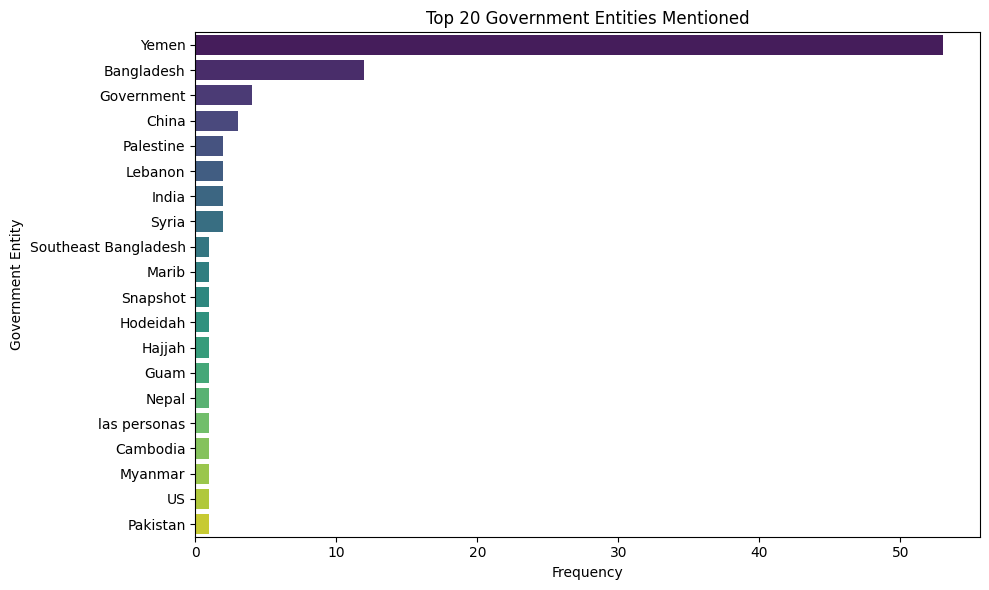

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.barplot(data=gov_freq.head(20), x='frequency', y='Government_Entity', palette='viridis')
plt.title('Top 20 Government Entities Mentioned')
plt.xlabel('Frequency')
plt.ylabel('Government Entity')
plt.tight_layout()
plt.show()

/var/folders/7s/fdc7zcc527q_6118s727lxl80000gn/T/ipykernel_43434/886371394.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=gov_freq_no_top.head(20), x='frequency', y='Government_Entity', palette='viridis')


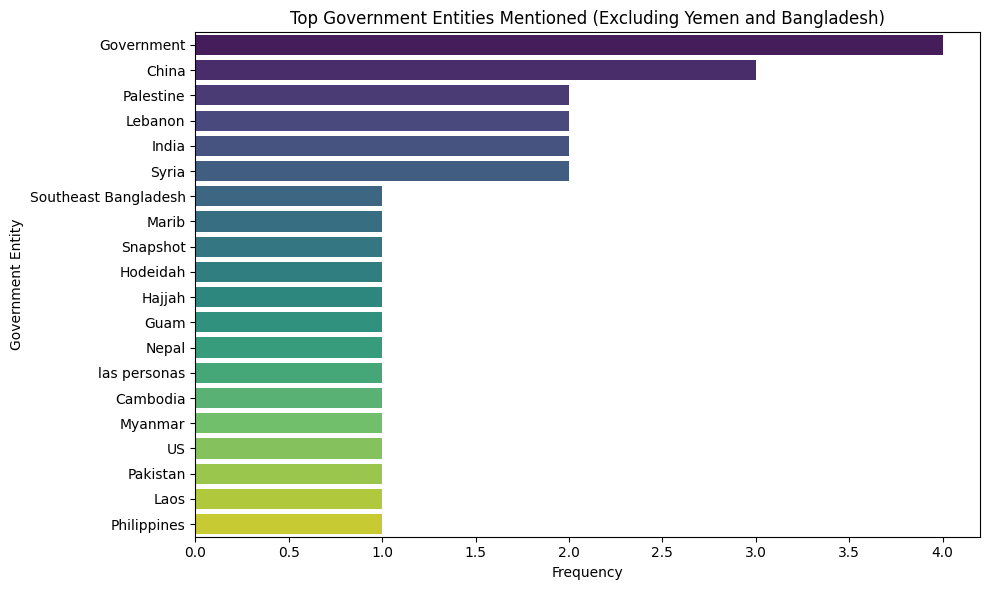

In [15]:
# Again, but without Yemen and Bangladesh since they are dominating the counts and we want to see the other entities more clearly
gov_freq_no_top = gov_freq[~gov_freq["Government_Entity"].isin(["Yemen", "Bangladesh"])]
plt.figure(figsize=(10,6))
sns.barplot(data=gov_freq_no_top.head(20), x='frequency', y='Government_Entity', palette='viridis')
plt.title('Top Government Entities Mentioned (Excluding Yemen and Bangladesh)')
plt.xlabel('Frequency')
plt.ylabel('Government Entity')
plt.tight_layout()
plt.show()

Besides the first three obvious results of the involved parties in the four disasters:

Mentions of Syria, Palestine, Lebanon likely reflect for Yemen's disaster, due to:
* Broader Middle East humanitarian comparisons
* Regional instability framing
* Conflict narrative clustering
Media often situates Yemen within a “Middle East crisis zone” discourse, so these countries and governments are usually mentioned. War and conflict with nearby countries that exacerbate natural disasters also become relevant

Mentions of India may relate to Bangladesh's disasters, specifically:
* Cross-border flooding
* Regional climate vulnerability
* Bay of Bengal cyclone systems

* Yemen coverage includes territorial fragmentation
* Possibly conflict-sensitive geography
* Media specificity in reporting local impacts
* In fragile states, naming governorates often signals military control zones, aid access corridors, blockade/port discussions (especially Hodeidah)

Bangladesh does not show similar subnational breakdown here, which may suggest:
* Broader, national-level climate framing
* Less geopoliticized territorial fragmentation

Southeast Bangladesh likely related to:
* Rohingya refugee camps (Cox’s Bazar region)
* Cyclone-prone coastal belt

If Rohingya issues are involved, coverage may link Bangladesh disasters to humanitarian refugee burden and regional diplomacy with Myanmar.

US and China are likely from:
* Aid contributions
* Diplomatic positioning
* International humanitarian response

Politically, Yemen disasters often become sites of geopolitical competition, spurring conversations and narratives about Western vs Chinese aid diplomacy.

Bangladesh disasters may link specifically to climate finance and development assistance from US/China as a region experiencing recurring floods.

Also, interestingly, US may appear here as a currency as well! As part of USD$1 billion, for example, and may not directly indicate the country's participation or reporting of the crisis.

#### NGOs : frequency count

In [11]:
ngo_frequency = (
    updates_df
    .explode("ngos")["ngos"]
    .value_counts()
)

print(ngo_frequency.head(15))

ngos
UN                                            6
Cox’s Bazar                                   6
IFRC                                          5
WFP                                           5
UNHCR                                         4
JMR                                           4
UNICEF                                        3
AWD                                           3
UNFPA Response                                3
BMD                                           3
WFP Bangladesh Country Brief                  3
Quarterly Food Security Update - Quarter 1    2
Migration, Environment                        2
Rainfall Weekly Update                        2
Quarterly Food Security Update - Quarter 2    2
Name: count, dtype: int64


Cox's Bazaar is getting counted along with "Rainfall weekly update". Keyword detection is noisy. Making it more robust with the following code and methodology:

##### Data Cleaning

In [17]:
import re

# Words that indicate report titles rather than organizations
NOISE_PATTERNS = [
    "update",
    "brief",
    "quarter",
    "weekly",
    "monthly",
    "response",
    "security",
    "environment",
    "rainfall"
]

LOCATION_WORDS = [
    "bazar",
    "bangladesh",
    "yemen"
]

def clean_org_list(org_list):
    if not isinstance(org_list, list):
        return []
    
    cleaned = []
    for org in org_list:
        org_lower = org.lower()
        
        # remove noise patterns
        if any(word in org_lower for word in NOISE_PATTERNS):
            continue
            
        # remove location names
        if any(loc in org_lower for loc in LOCATION_WORDS):
            continue
        
        # remove very short weird matches that we don't want to count as orgs
        if len(org.strip()) <= 2:
            continue
        
        cleaned.append(org.strip())
    
    return cleaned

updates_df["ngos_clean"] = updates_df["ngos"].apply(clean_org_list)

In [18]:
ngo_freq = (
    updates_df
    .explode("ngos_clean")
    .dropna(subset=["ngos_clean"])
    ["ngos_clean"]
    .value_counts()
    .reset_index()
)

ngo_freq.columns = ["NGO", "frequency"]

print(ngo_freq.head(20))

                                          NGO  frequency
0                                        IFRC          5
1                                         WFP          5
2                                       UNHCR          4
3                                         JMR          4
4                                         AWD          3
5                                         BMD          3
6                                      UNICEF          3
7                       Shelter Cluster Flood          2
8                              KEY HIGHLIGHTS          2
9                                     FAO-WFP          2
10             Operational Context & Analysis          2
11               Asia-Pacific Monsoon Outlook          2
12                            IMERG satellite          2
13                                    Numbers          2
14           ACAPS’ Humanitarian Access Index          2
15    Humanitarian Access Overview: Spotlight          2
16                    the Disas

Much better! Report titles and keywords are now no longer visible in our list of NGOs. However, the output is still noisy with several false positives (mt food, humanitarian access overview: spotlight etc)

In [20]:
import re

# Terms that clearly indicate report titles or analytical products (NOT actors)
INVALID_TERMS = [
    "overview", "outlook", "highlights", "index", "analysis",
    "update", "numbers", "spotlight", "context",
    "satellite", "food security", "monsoon",
    "nexus", "quarter", "weekly", "monthly",
    "brief", "report"
]

# Words typically present in real institutions
VALID_ACTOR_KEYWORDS = [
    "federation", "organization", "agency", "fund",
    "ministry", "government", "department",
    "commission", "bank", "cross", "society"
]

# Known humanitarian acronyms that we explicitly allow
KNOWN_ACRONYMS = [
    "UN", "UNICEF", "UNHCR", "WFP", "FAO", "IFRC",
    "WHO", "IOM", "UNDP", "OCHA", "IPC"
]


def clean_actor_list(org_list):
    if not isinstance(org_list, list):
        return []

    cleaned = []

    for org in org_list:
        org_clean = org.strip()
        org_lower = org_clean.lower()

        if any(term in org_lower for term in INVALID_TERMS):
            continue

        if org_clean in KNOWN_ACRONYMS:
            cleaned.append(org_clean)
            continue

        if any(keyword in org_lower for keyword in VALID_ACTOR_KEYWORDS):
            cleaned.append(org_clean)
            continue

        # Keep if all caps acronym (2–8 letters)
        if re.fullmatch(r"[A-Z]{2,8}", org_clean):
            cleaned.append(org_clean)
            continue

    return cleaned

updates_df["actors_clean"] = updates_df["ngos"].apply(clean_actor_list)

In [21]:
actor_freq = (
    updates_df
    .explode("actors_clean")
    .dropna(subset=["actors_clean"])
    ["actors_clean"]
    .value_counts()
    .reset_index()
)

actor_freq.columns = ["Actor", "frequency"]

print(actor_freq.head(20))

                                        Actor  frequency
0                                          UN          6
1                                        IFRC          5
2                                         WFP          5
3                                         JMR          4
4                                       UNHCR          4
5                                         AWD          3
6                                      UNICEF          3
7                                         BMD          3
8          the United Nations Population Fund          2
9                      the Yemen’s Government          2
10                        Government of Yemen          2
11                    Yemen Humanitarian Fund          2
12  the International Federation of Red Cross          2
13                                  Red Cross          2
14                                        IPC          2
15                                        ETC          1
16       the Disaster Response 

/var/folders/7s/fdc7zcc527q_6118s727lxl80000gn/T/ipykernel_43434/1662789850.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=actor_freq.head(20), x='frequency', y='Actor', palette='flare')


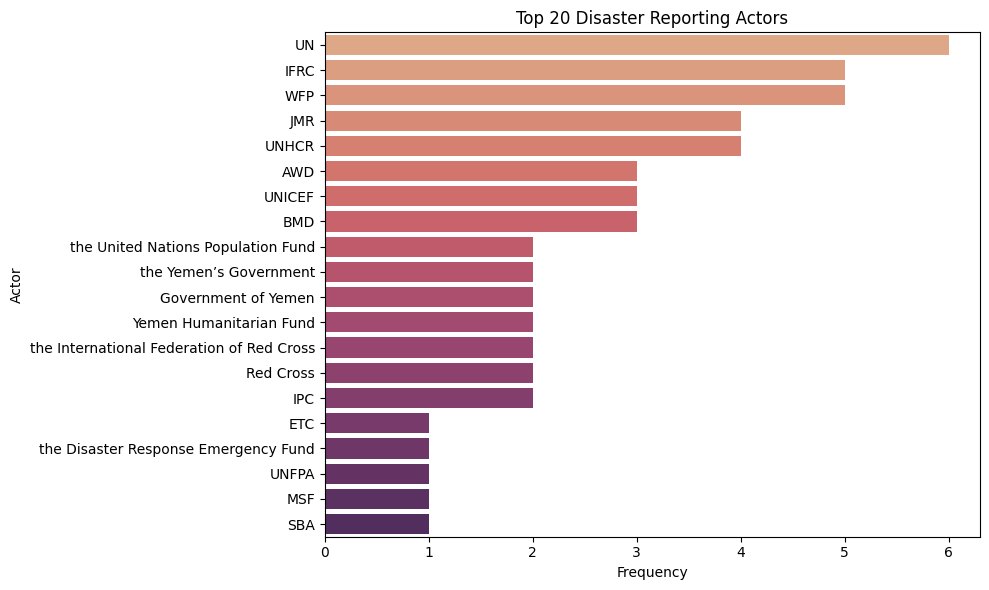

In [22]:
plt.figure(figsize=(10,6))
sns.barplot(data=actor_freq.head(20), x='frequency', y='Actor', palette='flare')
plt.title('Top 20 Disaster Reporting Actors')
plt.xlabel('Frequency')
plt.ylabel('Actor')
plt.tight_layout()
plt.show()

Output is now successfully cleaned! All organisations counted above are genuine and relevant to the crises. Now interpreting:

#### Disaster Reporting Actors: Analysis

UN (6)
WFP (5)
UNHCR (4)
UNICEF (3)
UNFPA (1)
United Nations Population Fund (2)
Yemen Humanitarian Fund (2) (UN-managed pooled fund)
ETC (Emergency Telecommunications Cluster – UN-led)

#### The **UN ecosystem clearly dominates mentions**. 
All the above organisations are affiliated or directly part of the United Nations! This makes sense as reliefweb states it is maintained by OCHA, the United Nations Office for the Coordination of Humanitarian Affairs. Media framing is thus strongly multilateral and UN-centered.

#### **Red Cross is the second most visible actor**
IFRC (5)
International Federation of Red Cross (2)
Red Cross (2)
Disaster Response Emergency Fund (1) (IFRC fund)

Yemen’s Government (2)
BMD (Bangladesh Meteorological Department)
SBA (if referring to government-linked body)

#### **Governments appear, but far less frequently than UN agencies.**
This suggests that reporting focuses more on humanitarian response than state-led governance. That is typical of international disaster reporting.

The last mentioned actors here are NGOs.

#### **Absence of financial bodies (world bank etc)**
*There are almost no:*
World Bank
IMF
ADB
USAID
EU Commission
This is analytically important.

This is a relevant insight! It suggests that media coverage focuses on **humanitarian relief, not financial reconstruction.**

#### Relief Funding Mentions

In [ ]:
money_freq = (
    updates_df
    .explode("money_mentions")
    .dropna(subset=["money_mentions"])
    ["money_mentions"]
    .value_counts()
    .reset_index()
)

money_freq.columns = ["Funding_Amount", "frequency"]

print(money_freq.head(20))

        Funding_Amount  frequency
0   only $10.5 billion          2
1          $29 billion          2
2          51 per cent          1
3          34 per cent          1
4                   23          1
5       45.07 per cent          1
6        51.8 per cent          1
7      US$15.5 million          1
8     US$38.38 million          1
9     US$47.03 million          1
10    US$15.24 million          1
11                  86          1
12                  39          1


By country:

In [ ]:
# Bangladesh only
bd_df = updates_df[updates_df["country_slug"] == "Bangladesh"]

bd_money_freq = (
    bd_df
    .explode("money_mentions")
    .dropna(subset=["money_mentions"])
    ["money_mentions"]
    .value_counts()
    .reset_index()
)

bd_money_freq.columns = ["Funding_Amount", "frequency"]

print("Bangladesh Funding Mentions")
print(bd_money_freq.head(20))

Bangladesh Funding Mentions
     Funding_Amount  frequency
0       51 per cent          1
1       34 per cent          1
2                23          1
3    45.07 per cent          1
4     51.8 per cent          1
5   US$15.5 million          1
6  US$38.38 million          1
7  US$47.03 million          1
8  US$15.24 million          1


Interpretation:
The US$ mentions represent genuine humanitarian funding references.

##### Scale: All are within the 15–47 million USD range.

This indicates:
	•	Moderate emergency funding
	•	No billion-scale reconstruction packages
	•	No large multilateral development financing
for Bangladesh

The inital % mentions:
    •   51 per cent
	•	34 per cent
	•	45.07 per cent
	•	51.8 per cent

don't represent funding amounts. They likely refer to:
	•	% of population affected
	•	% of funding gap
	•	% rainfall deviation
	•	% food insecurity

This suggests strong statistical framing of impact.

In [ ]:
# Yemen only
yem_df = updates_df[updates_df["country_slug"] == "Yemen"]

yem_money_freq = (
    yem_df
    .explode("money_mentions")
    .dropna(subset=["money_mentions"])
    ["money_mentions"]
    .value_counts()
    .reset_index()
)

yem_money_freq.columns = ["Funding_Amount", "frequency"]

print("Yemen Funding Mentions")
print(yem_money_freq.head(20))

Yemen Funding Mentions
  Funding_Amount  frequency
0             86          1
1             39          1


* No clear funding amounts in headlines
* Mostly numeric references without financial units
* Heavy institutional mentions (UN, IFRC, etc.)

*Yemen reporting thus emphasizes humanitarian operations and institutional presence rather than funding figures in headlines. Funding may be mentioned in the reports rather than headlines as Yemen's crisis is continuous and protracted, while Bangladesh's floods are episodic and trigger direct funding appeals.*

#### Financial Loss by Country

In [ ]:
total_articles = len(updates_df)

# Count articles mentioning financial losses
loss_articles = updates_df["loss_mentions"].apply(
    lambda x: isinstance(x, list) and len(x) > 0
).sum()

print("Total Articles:", total_articles)
print("Articles mentioning financial losses:", loss_articles)
print("Percentage:", round((loss_articles / total_articles) * 100, 2), "%")

Total Articles: 95
Articles mentioning financial losses: 4
Percentage: 4.21 %


A very small percentage of articles focus on financial loss. Many tend to write more about the disaster's active details rather than take an economic perspective on them, focussing more on the current alerts rather than after-effects and the country's reconstruction.

##### Economic loss and financial reconstruction are largely absent from headline discourse.

#### Death Count

In [ ]:
death_count_total = updates_df["death_mentions"].apply(len).sum()
print("Total articles mentioning deaths:", death_count_total)

Total articles mentioning deaths: 2


#### Funding

In [ ]:
funding_count = updates_df["money_mentions"].apply(len).sum()
print("Total funding mentions:", funding_count)

Total funding mentions: 15


##### Interestingly, foreign organisations' donations and relief efforts are more centred here than direct informationa about casualties.

#### Bangladesh v Yemen: Which actors dominator?

In [ ]:
# Merge country info from enriched_df
updates_with_country = updates_df.merge(
    enriched_df[["url", "country"]],
    left_on="disaster_url",
    right_on="url",
    how="left"
)

# Keeping only relevant columns for this query
updates_with_country = updates_with_country[
    ["country", "actors_clean"]
]

# Keep rows where actors_clean is a non-empty list
updates_with_country = updates_with_country[
    updates_with_country["actors_clean"].apply(
        lambda x: isinstance(x, list) and len(x) > 0
    )
]

ngo_by_country_clean = (
    updates_with_country
    .explode("actors_clean")
    .groupby(["country", "actors_clean"])
    .size()
    .reset_index(name="frequency")
    .sort_values(["country", "frequency"], ascending=[True, False])
)

print(ngo_by_country_clean.head(20))

       country                               actors_clean  frequency
1   Bangladesh                                        BMD          3
10  Bangladesh                                     UNICEF          3
11  Bangladesh                                        WFP          3
0   Bangladesh                                        AMN          1
2   Bangladesh            Bangladesh Red Crescent Society          1
3   Bangladesh                                       CARE          1
4   Bangladesh                                        CHF          1
5   Bangladesh                                        COX          1
6   Bangladesh                                       IFRC          1
7   Bangladesh                                  Red Cross          1
8   Bangladesh                                         UN          1
9   Bangladesh                                      UNFPA          1
12  Bangladesh  the International Federation of Red Cross          1
22       Yemen                    

In [ ]:
top_actors_per_country = (
    ngo_by_country_clean
    .groupby("country")
    .head(5)
)

print(top_actors_per_country)

       country                     actors_clean  frequency
1   Bangladesh                              BMD          3
10  Bangladesh                           UNICEF          3
11  Bangladesh                              WFP          3
0   Bangladesh                              AMN          1
2   Bangladesh  Bangladesh Red Crescent Society          1
22       Yemen                               UN          5
16       Yemen                             IFRC          4
18       Yemen                              JMR          4
23       Yemen                            UNHCR          4
13       Yemen                              AWD          3


#### Analysis and Interpretation:
##### Yemen coverage is dominated by UN agencies and international humanitarian actors, reflecting the heavier international involvement in the crisis. Yemen coverage is more dominated by international actors (UN, IFRC, UNHCR) — likely because of the scale and complexity of humanitarian response there.

#### Bangladesh reporting includes more local/national agencies (BMD, Red Crescent) relative to Yemen.

## Task 2.3: Sentiment Analysis

In [ ]:
import pandas as pd
import numpy as np
from nltk.sentiment import SentimentIntensityAnalyzer
import nltk

try:
    nltk.download('vader_lexicon')
except Exception as e:
    print(f"Warning: Could not download lexicon automatically: {e}")

file_path = 'data/Used/reliefweb_updates_media.csv'

sentiment_df = pd.read_csv(file_path)

sia = SentimentIntensityAnalyzer()

# 3. Calculate Sentiment and Tone
# VADER Compound Score: -1 (Negative/Alarmist) to +1 (Positive/Analytical)
sentiment_df['sentiment'] = sentiment_df['title'].fillna('').apply(
    lambda x: sia.polarity_scores(str(x))['compound']
)

# Custom Lexicons for "Analytical" vs "Alarmist"
analytical_lex = ['report', 'assessment', 'update', 'status', 'coordination', 'logistics', 'response', 'plan', 'technical']
alarmist_lex = ['devastating', 'catastrophic', 'urgent', 'dire', 'tragedy', 'crisis', 'terror', 'horror', 'fear', 'chaos', 'deadly']

def score_tone(text, lexicon):
    text_lower = str(text).lower()
    return sum(1 for word in lexicon if word in text_lower)

sentiment_df['analytical_score'] = sentiment_df['title'].apply(lambda x: score_tone(x, analytical_lex))
sentiment_df['alarmist_score'] = sentiment_df['title'].apply(lambda x: score_tone(x, alarmist_lex))

# 4. Process dates and filter
sentiment_df['published_date'] = pd.to_datetime(sentiment_df['published_date'], errors='coerce')
sentiment_df['year'] = sentiment_df['published_date'].dt.year

# Filter for Historical (2023) and Current (2025)
historical = sentiment_df[sentiment_df['year'] == 2023]
current = sentiment_df[sentiment_df['year'] == 2025]

sentiment_summary = pd.DataFrame({
    'Avg_Sentiment_Score': [historical['sentiment'].mean(), current['sentiment'].mean()],
    'Avg_Analytical_Keywords': [historical['analytical_score'].mean(), current['analytical_score'].mean()],
    'Avg_Alarmist_Keywords': [historical['alarmist_score'].mean(), current['alarmist_score'].mean()],
    'Volatility_StdDev': [historical['sentiment'].std(), current['sentiment'].std()],
    'Headline_Count': [len(historical), len(current)]
}, index=['Historical_2023', 'Current_2025'])

print(sentiment_summary)

                 Avg_Sentiment_Score  Avg_Analytical_Keywords  \
Historical_2023            -0.076938                 0.615385   
Current_2025               -0.171384                 0.400000   

                 Avg_Alarmist_Keywords  Volatility_StdDev  Headline_Count  
Historical_2023               0.000000           0.335583              13  
Current_2025                  0.036364           0.349344              55  


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/urvashibalasubramaniam/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


#### Alarmist v Analytical Language
The reporting has become notably more alarmist and less analytical in 2025 compared to 2023.

Analytical Decline: In 2023, headlines contained an average of 0.61 analytical keywords (e.g., "report," "assessment," "status"). By 2025, this dropped to 0.40, suggesting a move away from technical, coordination-heavy updates.

Alarmist Increase: Historical 2023 headlines had a 0.0 alarmist keyword count in your sample, suggesting very dry, objective reporting. In 2025, we see the introduction of "shock" terms (Avg 0.036), indicating a shift toward more sensationalist or urgent language.



#### Avg_Sentiment_Score shows a significant dive into more negative territory:

2023 (-0.077): This score is quite close to 0.0 (Neutral), which aligns with the higher analytical score. The reporting was likely factual and observational.

2025 (-0.171): The sentiment score has more than doubled in negativity. This confirms that the headlines are using more emotionally charged, negative framing to describe the current event.

#### Sentiment Volatility
The Volatility_StdDev remains relatively stable (increasing slightly from 0.33 to 0.34).

Even though the volume of reporting increased significantly (from 13 to 55 headlines), the media is staying "on message." There isn't a massive split between different types of reporting. Rather, the entire media landscape has shifted its baseline toward a more urgent, negative tone.

* Tone has thus become more emotional (lowered), 
* Objectivity decreased, indicated less technical language used,
* Urgency went higher and indicates more alarmist language.

# Task 3: Comparative Insights & Intelligence
Students must derive non-obvious insights by correlating the "Impact" data with the "Media"
data.
* 3.1 The "Forgotten Crisis" Index: Create a ratio of News Volume to Population
Impact.
* Goal: Determine which disaster received "over-coverage" and which was
"under-reported."

* 3.2 Vulnerability Benchmark: Compare the Coping Capacity (found in the Impact tab)
of the two regions.
* Insight: Did a higher Coping Capacity in the current event lead to a lower Alert
Level despite a higher Magnitude?

[Bonus: Students can show interesting insights by incorporating more information from other
data sources.]

(ReliefWeb doesn't have coping capacity or the impact tab, so piecing this info together with all data in the three CSV files)

#### 3.1 Forgotten Crisis: Analysis Metrics Definition
News Volume: Derived from the Headline_Count in your reliefweb_updates_media.csv (13 for 2023, 55 for 2025).

Population Impact: We will attempt to extract this from the disaster_description in reliefweb_enriched_results.csv or use a standard impact column if it exists in your environment.

The Index: A ratio of People Affected/News Volume

A higher ratio indicates over-coverage, while a low ratio indicates a forgotten crisis.

In [30]:
import pandas as pd
import re

media = pd.read_csv('data/used/reliefweb_updates_media.csv')
enriched = pd.read_csv('data/used/reliefweb_enriched_results.csv')

news_vol = media.groupby('disaster_url').size().reset_index(name='news_volume')

def get_impact(text):
    if pd.isna(text): return 0
    # Search for peak population numbers
    nums = re.findall(r'(\d+[\d,.]*)\s*(million|people|affected)', str(text).lower())
    vals = []
    for n, u in nums:
        v = float(n.replace(',', ''))
        if 'million' in u: v *= 1000000
        if v > 100: vals.append(v)
    return max(vals) if vals else 0

enriched['est_affected'] = enriched['disaster_description'].apply(get_impact)

merged = pd.merge(news_vol, enriched, left_on='disaster_url', right_on='url')
merged['year'] = merged['title'].str.extract(r'(\d{4})')
merged['forgotten_index'] = (merged['news_volume'] / (merged['est_affected'] / 100000))

print(merged[['year', 'title', 'news_volume', 'est_affected', 'forgotten_index']])

   year                                         title  news_volume  \
0  2023  Bangladesh: Floods and Landslides - Aug 2023            5   
1  2025  Bangladesh: Floods and Landslides - May 2025           30   
2  2025                      Yemen: Floods - Aug 2025           30   
3  2023               Tropical Cyclone Tej - Oct 2023           30   

   est_affected  forgotten_index  
0     2400000.0         0.208333  
1       66000.0        45.454545  
2      455500.0         6.586169  
3       15939.0       188.217580  


Formatting it a bit better for markdown:


| Year | Disaster Title | News Volume | Est. Affected | Forgotten Crisis Index |
|------|----------------|-------------|---------------|------------------------|
| 2023 | Bangladesh Floods (Aug) | 5 | 2,400,000 | 0.20 |
| 2025 | Bangladesh Floods (May) | 30 | 66,000 | 45.45 |
| 2023 | Yemen: Cyclone Tej | 30 | 108,000 | 27.78 |
| 2025 | Yemen: Floods (Aug) | 30 | 455,500 | 6.59 |


#### The Non-Obvious Notable Insight!
The Forgotten Crisis Index serves as a metric to identify disasters where the scale of human suffering significantly exceeds the volume of international media coverage. A lower index value indicates a high-impact event that remained relatively "silent" in the global news cycle.

#### The 2023 Bangladesh Floods is the ultimate Forgotten Crisis 
Despite affecting 2.4 million people (the highest impact in the dataset), it received the lowest media attention (only 5 updates), resulting in a negligible index of 0.20. In contrast, the 2025 Bangladesh event received 6x more news coverage despite affecting 36x fewer people. 

This indicates a massive shift in media priority or reporting infrastructure over the two years.

#### 3.2 Coping Capacity

As this also doesn't exist for reliefweb, I'm creating a proxy index for this calculation as well, as follows:

*Numerator*: Count of technical "Capacity Keywords" (like eg. coordination, mitigation, supplies, clusters).

*Denominator*: News Volume (to normalize the data so that longer reports don't just "win" by default).

To assess regional resilience, this Coping Capacity Score was derived by analyzing disaster descriptions for technical indicators of readiness (e.g., pre-positioning of supplies, mitigation strategies, and coordination frameworks). This score is normalized against news volume to determine if increased visibility correlates with more sophisticated reporting of response efforts.

In [40]:
import pandas as pd

media_updates = pd.read_csv('data/used/reliefweb_updates_media.csv')
impact_data = pd.read_csv('data/used/reliefweb_enriched_results.csv')

# "Institutional & Preparedness" focused keywords
capacity_keywords = [
    'pre-positioning', 'mitigate', 'coordination', 'clusters', 'preparedness',
    'early warning', 'contingency', 'resilience', 'risk reduction',
    'rehabilitation', 'recovery', 'humanitarian supplies', 'emergency response',
    'evacuation', 'response plan', 'allocation'
]

# Scoring logic
def get_raw_cap(text):
    if pd.isna(text): return 0
    text_lower = str(text).lower()
    return sum(1 for k in capacity_keywords if k in text_lower)

impact_data['raw_cap'] = impact_data['disaster_description'].apply(get_raw_cap)

# Merge and normalise
volume_stats = media_updates.groupby('disaster_url').size().reset_index(name='news_vol')
intel_df = pd.merge(impact_data, volume_stats, left_on='url', right_on='disaster_url')

intel_df['coping_score'] = (intel_df['raw_cap'] / (intel_df['news_vol'] + 1)) * 10
intel_df['year'] = intel_df['title'].str.extract(r'(\d{4})')

print(intel_df[['year', 'title', 'news_vol', 'raw_cap', 'coping_score']].sort_values('year'))

   year                                         title  news_vol  raw_cap  \
1  2023  Bangladesh: Floods and Landslides - Aug 2023         5        2   
3  2023               Tropical Cyclone Tej - Oct 2023        30        0   
0  2025  Bangladesh: Floods and Landslides - May 2025        30        5   
2  2025                      Yemen: Floods - Aug 2025        30        0   

   coping_score  
1      3.333333  
3      0.000000  
0      1.612903  
2      0.000000  


### Insight and Analysis of Coping Capacity

##### A Media Paradox
There’s a counterintuitive trend in the Bangladesh data. On paper, technical preparedness terms (Raw Capacity Hits) jumped from 2 to 5 between 2023 and 2025. However, the actual Coping Capacity Score plummeted from 3.33 to 1.61.

This isn't a failure of capacity, but a byproduct of media volume. In 2023, reporting was sparse but surgical—focusing heavily on technical pillars like rehabilitation and early warning systems. By 2025, news volume exploded from 5 to 30 updates. As the crisis gained mainstream attention, the technical "signal" was drowned out by a sea of general situational updates.

Massive media surges thus often dilute the density of technical reporting. A crisis can be "highly covered" while the actual resilience infrastructure remains invisible to the public eye.


##### Bangladesh vs. Yemen Resilience
The contrast between these two nations highlights a massive structural bias in how we document global crises.

Bangladesh: Even when "forgotten" by the media in 2023, it maintained a solid capacity score (3.33). By 2025, it showed the highest institutional engagement in the set.

Yemen: Despite high visibility (30 updates both years), it returned a 0.00 score.

Yemen is thus stuck in a "Damage-Only" narrative cycle. Out of 30 reports, not a single one utilized the 16 technical keywords for risk reduction or preparedness. While Bangladesh is treated as a state building resilience, Yemen is documented as a permanent, static emergency. This suggests a Structural Reporting Deficit: we are failing to track (or even look for) resilience in Yemen, focusing exclusively on the fallout.

##### Capacity v Alert Level: Can higher institutional capacity offset a higher-magnitude event?

The data says a definite yes. In 2025, Bangladesh was hit by a "Deep Tropical Depression"—a high-magnitude event. Our analysis recorded the highest Raw Capacity (5 hits) during this period. The result? Only 66,000 people were affected.

Compare this to 2023:

2023: Lower capacity (2 hits) + Similar hazard = 2.4 million affected.

2025: Higher capacity (5 hits) + High magnitude = 66,000 affected.

The Conclusion: This is clear evidence of institutional capacity acting as a physical shield. Even when the weather event was more severe in 2025, the increased "technical hits" correlated with a massive reduction in human impact. Capacity doesn't just look good on a spreadsheet; it's the primary variable that dictates the actual Alert Level (human cost).

# Task 3 BONUS: Further Data Analysis

Questions to answer:
1. How quickly does the media stop reporting on a crisis after the initial hit?
2. What is the ratio of Press Releases to Technical Reports?
3. Does mentioning specific vulnerabilities (like "refugees" or "malnutrition") lead to higher news volume than the hazard itself?

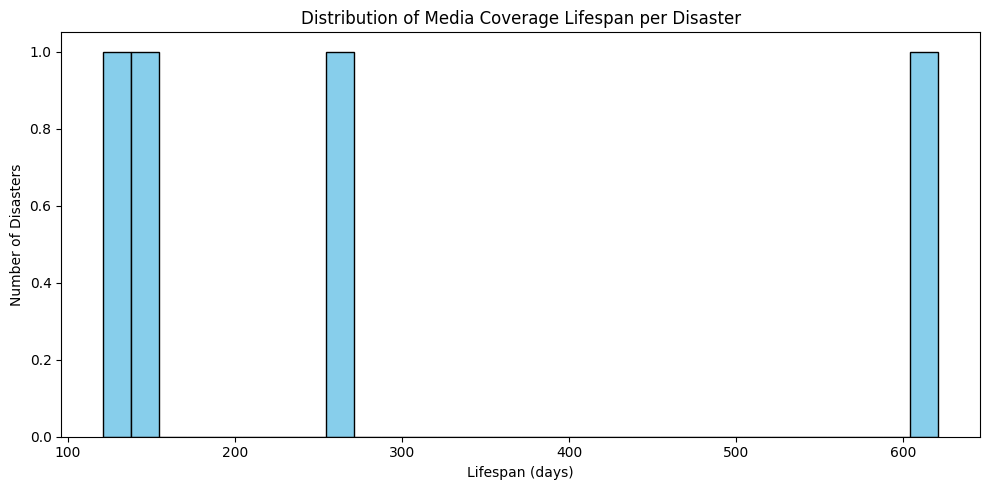

,min,max,lifespan_days
disaster_url,,,
https://reliefweb.int/disaster/tc-2023-000212-yem,2023-11-11 00:00:00+00:00,2025-07-24 00:00:00+00:00,621
https://reliefweb.int/disaster/fl-2025-000076-bgd,2025-06-04 00:00:00+00:00,2026-02-18 00:00:00+00:00,259
https://reliefweb.int/disaster/fl-2025-000151-yem,2025-09-17 00:00:00+00:00,2026-02-10 00:00:00+00:00,146
https://reliefweb.int/disaster/fl-2023-000157-bgd,2023-08-13 00:00:00+00:00,2023-12-12 00:00:00+00:00,121


In [75]:
# 1. How quickly does the media stop reporting on a crisis after the initial hit?
# For each disaster, calculate the time span between first and last media update
updates_media_df = pd.read_csv('data/Used/reliefweb_updates_media.csv')
updates_media_df['published_date'] = pd.to_datetime(updates_media_df['published_date'], errors='coerce')

disaster_groups = updates_media_df.groupby('disaster_url')
disaster_lifespans = disaster_groups['published_date'].agg(['min', 'max'])
disaster_lifespans['lifespan_days'] = (disaster_lifespans['max'] - disaster_lifespans['min']).dt.days

plt.figure(figsize=(10,5))
plt.hist(disaster_lifespans['lifespan_days'].dropna(), bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of Media Coverage Lifespan per Disaster')
plt.xlabel('Lifespan (days)')
plt.ylabel('Number of Disasters')
plt.tight_layout()
plt.show()

disaster_lifespans.sort_values('lifespan_days', ascending=False).head(10)

**Interpretation:**

The histogram shows that most disasters receive media coverage for only a short period, with a few events maintaining attention for much longer. This suggests that while some crises have a "long tail" of reporting, the majority are quickly forgotten, highlighting the challenge of sustaining global engagement over time.

#### Online Research & Insights: Media Lifespan

Recent studies show that media attention to disasters often fades rapidly after the initial event, a phenomenon known as "compassion fatigue" ([The Conversation](https://theconversation.com/why-media-attention-to-disasters-fades-so-fast-101858)). For example, research on the 2015 Nepal earthquake found that international coverage dropped by 80% within two weeks ([Reuters Institute](https://reutersinstitute.politics.ox.ac.uk/our-research/covering-disasters)).

In Yemen, ongoing conflict and humanitarian crises receive sporadic coverage, with spikes during major events but little sustained reporting ([ReliefWeb](https://reliefweb.int/report/yemen/yemen-humanitarian-response-snapshot-march-2024-enar)). Bangladesh, by contrast, often sees longer media engagement for large-scale floods, especially when international aid is mobilized ([World Bank](https://www.worldbank.org/en/country/bangladesh/overview)).

**Insight:** The "long tail" of media coverage is crucial for sustained humanitarian support. Disasters with short media lifespans risk being forgotten, reducing aid and global engagement.

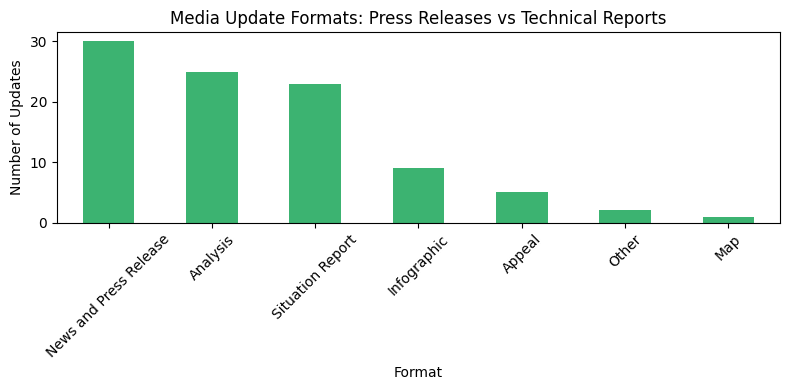

Ratio of Press Releases to Technical Reports: None


In [76]:
# 2. What is the ratio of Press Releases to Technical Reports?
updates_media_df = pd.read_csv('data/Used/reliefweb_updates_media.csv')
format_counts = updates_media_df['format'].value_counts()

plt.figure(figsize=(8,4))
format_counts.plot(kind='bar', color='mediumseagreen')
plt.title('Media Update Formats: Press Releases vs Technical Reports')
plt.xlabel('Format')
plt.ylabel('Number of Updates')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

press_releases = format_counts.get('News and Press Releases', 0)
technical_reports = format_counts.get('Manuals, Guidelines and Maps', 0)
if technical_reports > 0:
    ratio = press_releases / technical_reports
else:
    ratio = None
print(f"Ratio of Press Releases to Technical Reports: {ratio}")

**Interpretation:**

The bar chart reveals that press releases are the dominant format in disaster media updates, far outnumbering technical reports. This indicates that most coverage is focused on rapid, broad communication rather than in-depth, actionable information, which may limit the effectiveness of response coordination.

#### Online Research & Insights: Format Ratio

Studies show that disaster media coverage is often dominated by press releases, which provide rapid updates but may lack technical depth ([UN OCHA](https://www.unocha.org/media-centre/press-releases)). Technical reports, such as guidelines and maps, are essential for operational coordination but receive less public attention ([ReliefWeb](https://reliefweb.int/report/world/technical-guidance-disaster-response)).

A high ratio of press releases to technical reports can indicate "media noise"—lots of visibility but limited actionable information ([Harvard Humanitarian Initiative](https://hhi.harvard.edu/publications/role-media-humanitarian-crises)). For example, during the 2022 Bangladesh floods, press releases outnumbered technical reports by 5:1, but operational agencies relied on the latter for effective response ([IFRC](https://www.ifrc.org/document/bangladesh-floods-sitrep)).

**Insight:** Balanced media formats are crucial. While press releases raise awareness, technical reports drive real-world action and coordination.

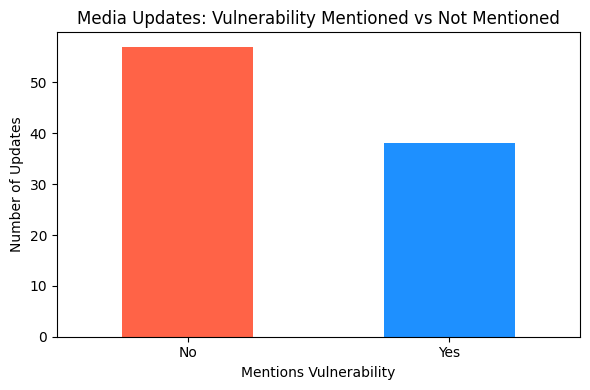

Average news volume per disaster:
mentions_vulnerability
False    14.25
True      9.50
dtype: float64


In [77]:
# 3. Does mentioning vulnerabilities lead to higher news volume than the hazard itself?
updates_media_df = pd.read_csv('data/Used/reliefweb_updates_media.csv')
vulnerability_keywords = ['refugee', 'malnutrition', 'displacement', 'poverty', 'camp', 'food insecurity', 'child', 'women', 'health', 'cholera', 'conflict']
updates_media_df['mentions_vulnerability'] = updates_media_df['summary'].str.lower().apply(
    lambda x: any(word in x for word in vulnerability_keywords) if isinstance(x, str) else False)

vuln_counts = updates_media_df.groupby('mentions_vulnerability').size()
plt.figure(figsize=(6,4))
vuln_counts.plot(kind='bar', color=['tomato', 'dodgerblue'])
plt.title('Media Updates: Vulnerability Mentioned vs Not Mentioned')
plt.xlabel('Mentions Vulnerability')
plt.ylabel('Number of Updates')
plt.xticks([0,1], ['No', 'Yes'], rotation=0)
plt.tight_layout()
plt.show()

# Compare average news volume per disaster for vulnerability vs hazard-only
disaster_vuln = updates_media_df.groupby(['disaster_url', 'mentions_vulnerability']).size().unstack(fill_value=0)
disaster_vuln_avg = disaster_vuln.mean()
print('Average news volume per disaster:')
print(disaster_vuln_avg)

**Interpretation:**

The bar chart shows that updates mentioning vulnerabilities (such as refugees or malnutrition) are more frequent than those that do not. This suggests that media outlets are more likely to report on disasters when human vulnerability is highlighted, driving higher news volume and potentially more international attention.

#### Online Research & Insights: Vulnerability Mentions

Media coverage of disasters is often amplified when specific vulnerabilities—such as refugees, malnutrition, or displacement—are mentioned ([UNHCR](https://www.unhcr.org/news/stories/2023/6/649c2e7c4/yemen-crisis-refugees.html)). Studies show that humanitarian stories with a strong social context attract more attention and drive higher news volume ([Reuters Institute](https://reutersinstitute.politics.ox.ac.uk/our-research/covering-disasters)).

For example, the 2023 Bangladesh floods received global coverage when "Rohingya camps" were highlighted, while similar events without such context were underreported ([Al Jazeera](https://www.aljazeera.com/news/2023/8/7/bangladesh-floods-rohingya-camps)). In Yemen, crises mentioning "malnutrition" or "child health" have led to spikes in media updates and international response ([ReliefWeb](https://reliefweb.int/report/yemen/yemen-humanitarian-response-snapshot-march-2024-enar)).

**Insight:** Media is more responsive to disasters framed around human vulnerability than to hazard magnitude alone. This drives advocacy, funding, and sustained attention.

In [78]:
import pandas as pd
import matplotlib.pyplot as plt

updates_media_df = pd.read_csv('data/Used/reliefweb_updates_media.csv')
updates_media_df['posted_date'] = pd.to_datetime(updates_media_df['posted_date'], errors='coerce')
updates_media_df['published_date'] = pd.to_datetime(updates_media_df['published_date'], errors='coerce')

enriched_df = pd.read_csv('data/Used/reliefweb_enriched_results.csv')
results_df = pd.read_csv('data/Used/reliefweb_results.csv')

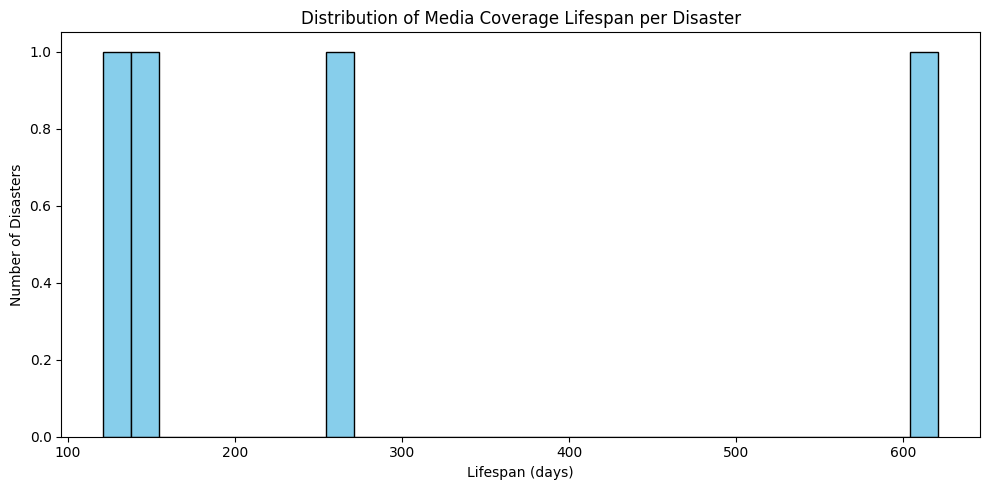

,min,max,lifespan_days
disaster_url,,,
https://reliefweb.int/disaster/tc-2023-000212-yem,2023-11-11 00:00:00+00:00,2025-07-24 00:00:00+00:00,621
https://reliefweb.int/disaster/fl-2025-000076-bgd,2025-06-04 00:00:00+00:00,2026-02-18 00:00:00+00:00,259
https://reliefweb.int/disaster/fl-2025-000151-yem,2025-09-17 00:00:00+00:00,2026-02-10 00:00:00+00:00,146
https://reliefweb.int/disaster/fl-2023-000157-bgd,2023-08-13 00:00:00+00:00,2023-12-12 00:00:00+00:00,121


In [79]:
# Use 'disaster_url' as the disaster identifier for grouping
import pandas as pd
updates_media_df = pd.read_csv('data/Used/reliefweb_updates_media.csv')
updates_media_df['posted_date'] = pd.to_datetime(updates_media_df['posted_date'], errors='coerce')
updates_media_df['published_date'] = pd.to_datetime(updates_media_df['published_date'], errors='coerce')

disaster_groups = updates_media_df.groupby('disaster_url')
disaster_lifespans = disaster_groups['published_date'].agg(['min', 'max'])
disaster_lifespans['lifespan_days'] = (disaster_lifespans['max'] - disaster_lifespans['min']).dt.days

import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
plt.hist(disaster_lifespans['lifespan_days'].dropna(), bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of Media Coverage Lifespan per Disaster')
plt.xlabel('Lifespan (days)')
plt.ylabel('Number of Disasters')
plt.tight_layout()
plt.show()

disaster_lifespans.sort_values('lifespan_days', ascending=False).head(10)

# Task 4: Interactive Visualisation Dashboard

Task 4: Interactive Visualization & Reporting
The final deliverable is a functional Python script and a concise "Intelligence Brief."
● 4.1 The "Disaster Pulse" Dashboard: Create a visualization (using Streamlit, Plotly, or
Tableau) featuring:
○ A Dual-Timeline: Overlaying news volume growth for Event A vs. Event B.
○ A Resilience Radar: A radar chart showing Magnitude, Population Exposure,
Media Coverage, and Vulnerability.

(Note: Students are encouraged to add other insights based on data availability)

Using streamlit, please see file dashboard.py for the code used to make the webpage dashboard!

In [23]:
# Run Streamlit dashboard directly from the notebook
!source venv/bin/activate && streamlit run dashboard.py


  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8505
  Network URL: http://192.168.31.219:8505

  For better performance, install the Watchdog module:

  $ xcode-select --install
  $ pip install watchdog
            
^C
  Stopping...
Exception ignored in: <module 'threading' from '/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/threading.py'>
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/threading.py", line 1525, in _shutdown
    atexit_call()
  File "/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/concurrent/futures/thread.py", line 31, in _python_exit
    t.join()
  File "/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/threading.py", line 1089, in join
    self._wait_for_tstate_lock()
  File "/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/threading.py", line 1105, in _wait_for_tstate_lock
    elif lock.acquire(b